# Augment rare cell types

A reference with few cells of some types trains a model that under-calls them.
`augment_data()` balances the classes: types below `norm_number` cells get simulated
cells, and with `prune=True` larger types are down-sampled. The simulated cells draw
molecules from the pooled counts of their type. This tutorial follows the R article
[How to augment data using viewmastR](https://furlan-lab.github.io/viewmastR/articles/Augment.html).

| Role | Dataset |
|---|---|
| Reference | BoneMarrowMap healthy bone marrow atlas (Zeng et al. 2025), 263,159 cells; broad labels `CellType_Broad` (24 types, 213 to 32,565 cells each) |
| Query | T-cell-depleted bone marrow, multiome RNA, 8,627 cells with the authors' labels and UMAP (Persad et al. 2023; the file the [Mellon](https://github.com/settylab/Mellon) tutorial uses) |

The steps below are the ones `tutorial_data.bonemarrowmap_augmented()` runs for tutorial 01,
with the same seeds, so both tutorials use the same reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
col = "CellType_Broad"
ref = td.bonemarrowmap_reference()  # 3.7 GB download on first use; about 12 GB in memory
print(ref.obs[col].value_counts().to_string())

CellType_Broad
Naive T                    32565
Monocyte                   28953
HSC MPP                    24003
CD4 Memory T               21051
Early Erythroid            19961
CD8 Memory T               16362
Early GMP                  11432
MEP                        11410
Late GMP                   10068
Cycling Progenitor          9366
Late Erythroid              8795
B                           8481
cDC                         8340
pDC                         8328
Pro-Monocyte                8079
NK                          7921
LMPP                        6718
Pro-B                       6027
Pre-B                       4701
Early Lymphoid              3809
Plasma_Cell                 2539
Megakaryocyte Precursor     2107
EoBasoMast Precursor        1930
Stromal                      213


## Hold out real cells for an honest test

Keep 20 % of the real cells of every type aside (at most 1,000 per type). Both models
below train on the other cells; only the second one is augmented. The held-out cells are
never simulated.

In [2]:
train, held = td.bonemarrowmap_split(ref, col, holdout=0.2, max_held=1000, seed=0)
del ref
print(train.shape, held.shape)

(242102, 34009) (21057, 34009)


## Augment to 3,000 cells per type

Types below 3,000 cells get simulated cells; with `prune=True` larger types are randomly
down-sampled to 3,000. The real cells that remain are the "not augmented" reference below,
so the two models differ only by the simulated cells.

In [3]:
aug = vm.augment_data(train, col, norm_number=3000, prune=True, seed=0)
aug.obs["simulated"] = aug.obs_names.str.startswith("stimcell_")
real = aug[~aug.obs["simulated"].to_numpy()].copy()
n = pd.DataFrame({"real cells": train.obs[col].value_counts(),
                  "kept": real.obs[col].value_counts(),
                  "simulated": aug.obs.loc[aug.obs["simulated"], col].value_counts(),
                  "after": aug.obs[col].value_counts()}).fillna(0).astype(int)
print(n.sort_values("real cells").to_string())
rare = n.index[n["simulated"] > 0]
del train

                         real cells  kept  simulated  after
CellType_Broad                                             
Stromal                         171   171       2829   3000
EoBasoMast Precursor           1544  1544       1456   3000
Megakaryocyte Precursor        1686  1686       1314   3000
Plasma_Cell                    2032  2032        968   3000
Early Lymphoid                 3048  3000          0   3000
Pre-B                          3761  3000          0   3000
Pro-B                          5027  3000          0   3000
LMPP                           5718  3000          0   3000
NK                             6921  3000          0   3000
Pro-Monocyte                   7079  3000          0   3000
pDC                            7328  3000          0   3000
cDC                            7340  3000          0   3000
B                              7481  3000          0   3000
Late Erythroid                 7795  3000          0   3000
Cycling Progenitor             8366  300

The simulated cells should sit with the real cells of their type in an embedding. This
check uses 300 cells per type. Here they land at the edge of their type's real cells,
often as a tight group: they share the pooled profile of their type, so they vary less
than real cells.

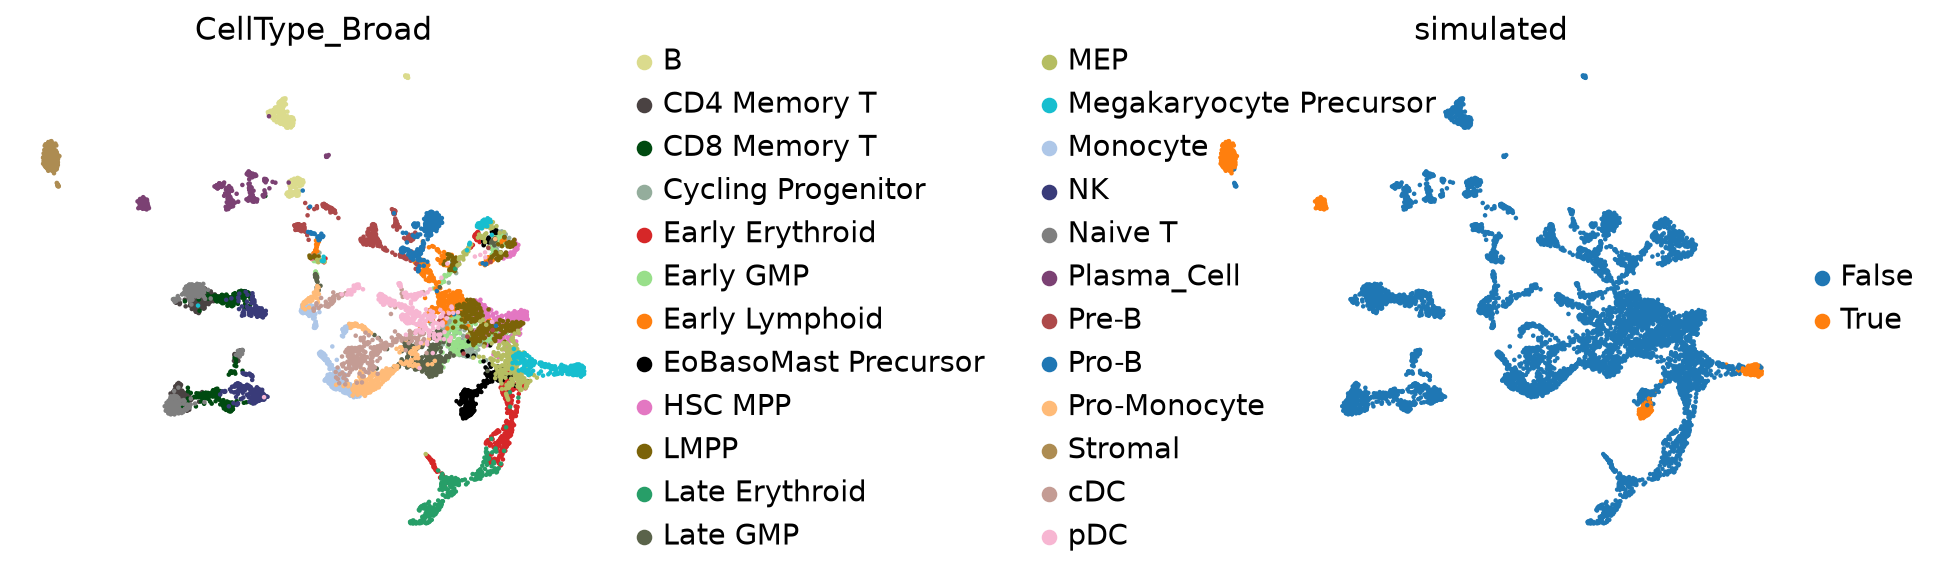

In [4]:
pick = aug.obs.groupby(col, observed=True).sample(300, random_state=0).index
a = aug[pick].copy()
a.obs["simulated"] = a.obs["simulated"].astype(str)
vm.palette.set_colors(a, col)
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
sc.pp.highly_variable_genes(a, n_top_genes=3000)
sc.pp.pca(a, n_comps=50, mask_var="highly_variable")
sc.pp.neighbors(a, n_pcs=40)
sc.tl.umap(a)
sc.pl.umap(a, color=[col, "simulated"], ncols=2, wspace=0.8)

## Does augmentation help the rare types?

Train one model on the real cells only and one on the augmented cells. Both use the genes
that vary in the reference and in the query. Then score both on the held-out real cells.
Recall = share of a type's held-out cells that get the right label. `seed` with
`workers=1` makes training reproducible.

In this atlas even the rarest type has 171 real training cells, and the model already
recalls the rare types well without simulated cells. Augmentation then changes little:
recall goes up for some rare types and down for others. It helped more when a type had
only tens of cells (a 20,000-cell subsample of this atlas showed that).

not augmented: accuracy 0.849, mean recall 0.858


augmented: accuracy 0.848, mean recall 0.858
                         not augmented  augmented
CellType_Broad                                   
EoBasoMast Precursor             0.834      0.863
Megakaryocyte Precursor          0.893      0.874
Plasma_Cell                      0.994      0.998
Stromal                          0.976      0.976


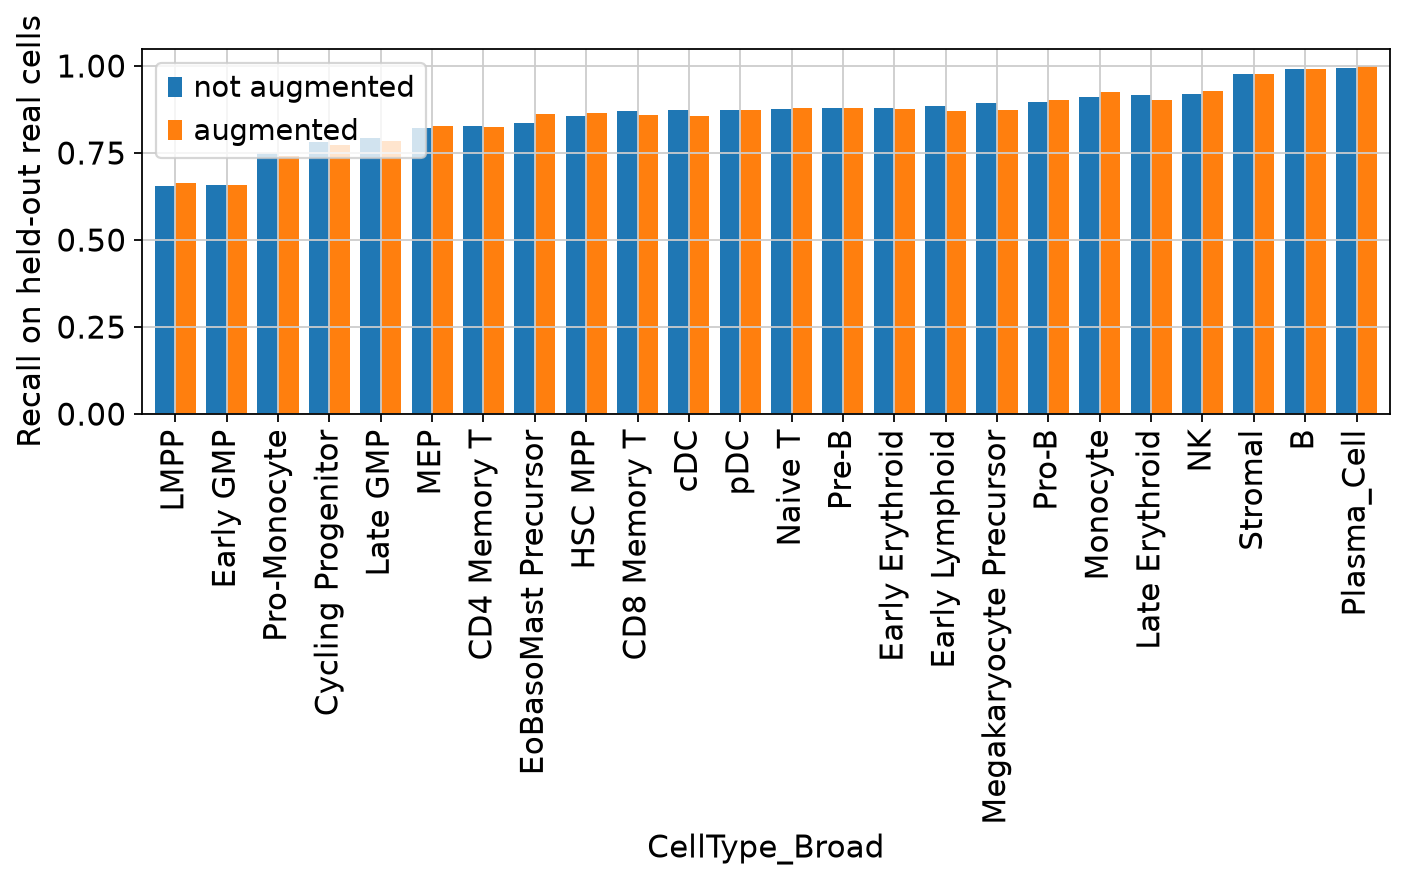

In [5]:
query = td.bm_tcelldep()  # raw counts, the authors' labels and their stored UMAP
vm.calculate_feature_dispersion(query)
vm.select_features(query, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
recall, models = {}, {}
for name, r in (("not augmented", real), ("augmented", aug)):
    vm.calculate_feature_dispersion(r)
    vm.select_features(r, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vgr = set(vm.get_selected_features(r))
    vg = [g for g in vm.get_selected_features(query) if g in vgr]
    res = vm.viewmastR(query, r, col, selected_features=vg, query_celldata_col=f"pred_{name}",
                       seed=20261103, workers=1, return_type="list", verbose=False)
    vm.viewmastR_infer(held, res.model_dir, query_celldata_col=f"pred_{name}")
    hit = held.obs[f"pred_{name}"].astype(str) == held.obs[col].astype(str)
    recall[name] = hit.groupby(held.obs[col], observed=True).mean()
    print(f"{name}: accuracy {hit.mean():.3f}, mean recall {recall[name].mean():.3f}")
recall = pd.DataFrame(recall)
print(recall.loc[rare].round(3).to_string())
recall.sort_values("not augmented").plot.bar(figsize=(10, 3), width=0.8)
plt.ylabel("Recall on held-out real cells")
plt.show()

## Label the query with the augmented reference

The query labels came from the augmented model in the loop above. Columns of the
confusion matrix are the authors' labels; rows are the predictions. The two vocabularies
differ, so read it as a mapping: for example, most author `Mono` cells map to atlas
`Pro-Monocyte` or `Monocyte`, and author `EryPre2` to `Late Erythroid`.

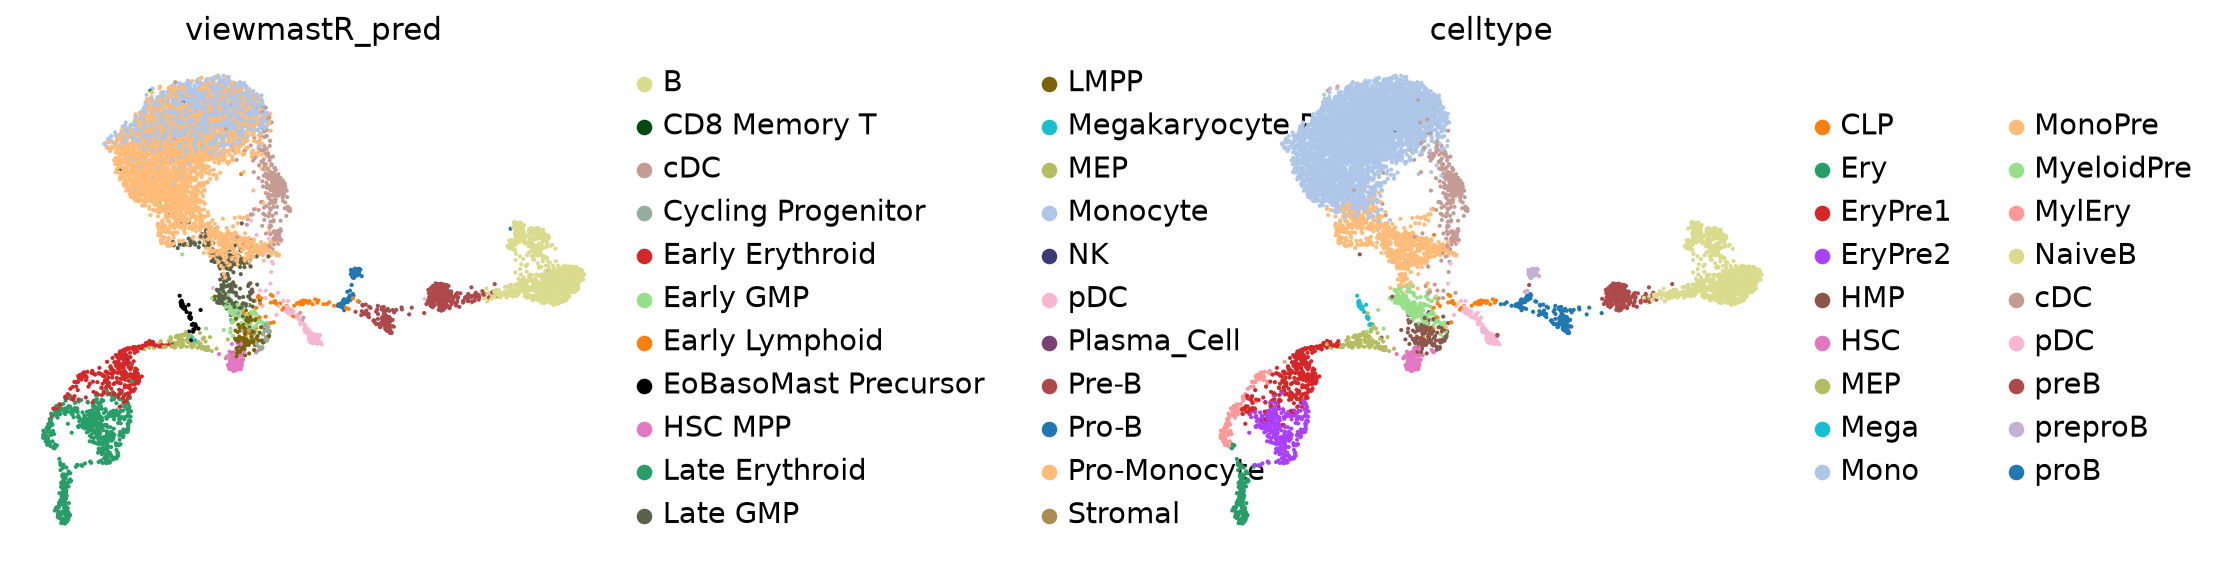

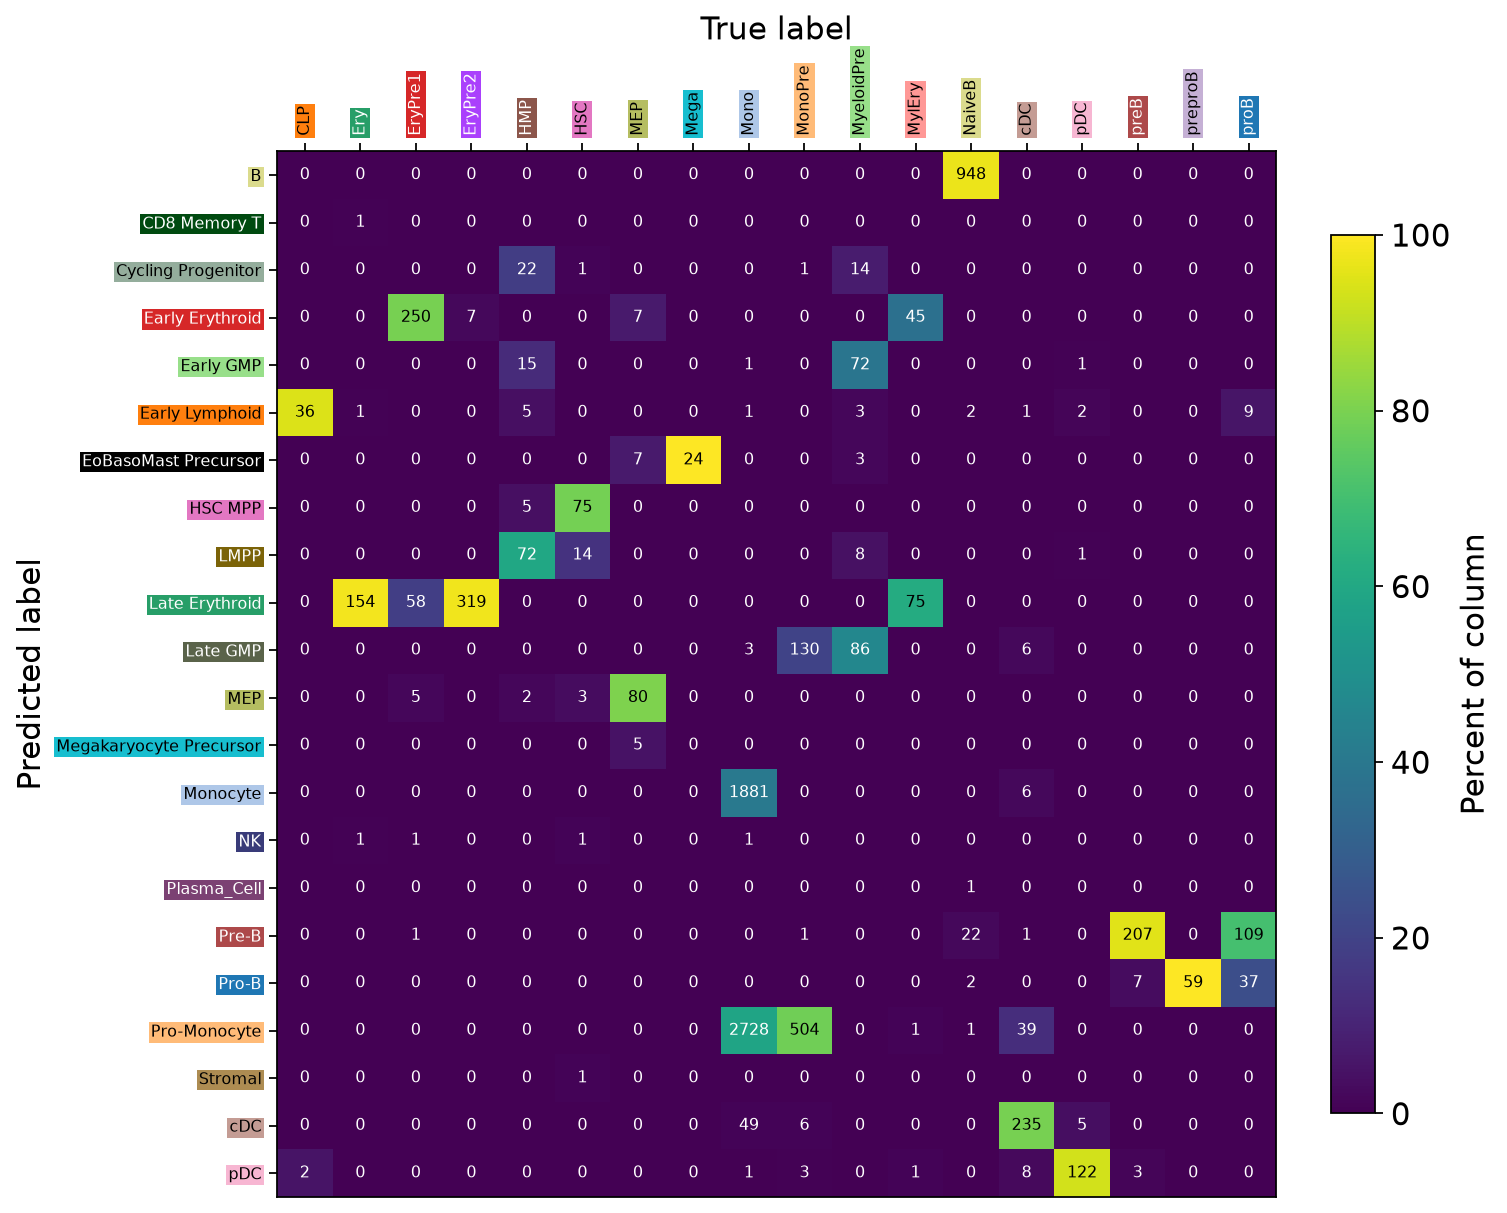

In [6]:
query.obs["viewmastR_pred"] = query.obs["pred_augmented"]
for key in ("viewmastR_pred", "celltype"):
    vm.palette.set_colors(query, key)
sc.pl.umap(query, color=["viewmastR_pred", "celltype"], ncols=2, wspace=0.8)
vm.confusion_matrix(query.obs["viewmastR_pred"], query.obs["celltype"],
                    cols=vm.palette.colors([*query.obs["viewmastR_pred"], *query.obs["celltype"]]))
plt.show()

Not translated: the R article first relabels regulatory T cells by cluster and a FOXP3
marker in its own PBMC data. The held-out test above replaces that example.

## Versions

In [7]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
